Student Performance in Exams

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
df = pd.read_csv(r"/Users/satwik/Downloads/StudentsPerformance.csv")
print("Data loaded successfully!!!")

Data loaded successfully!!!


In [8]:
print("first 5 rows of dataset : ")
print(df.head())

first 5 rows of dataset : 
   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  


In [9]:
print("last 5 rows of dataset : ")
print(df.tail())

last 5 rows of dataset : 
     gender race/ethnicity parental level of education         lunch  \
995  female        group E             master's degree      standard   
996    male        group C                 high school  free/reduced   
997  female        group C                 high school  free/reduced   
998  female        group D                some college      standard   
999  female        group D                some college  free/reduced   

    test preparation course  math score  reading score  writing score  
995               completed          88             99             95  
996                    none          62             55             55  
997               completed          59             71             65  
998               completed          68             78             77  
999                    none          77             86             86  


In [11]:
print(df.shape)

(1000, 8)


In [13]:
data = df["math score"].dropna()
print("\nnumber of math score values:",len(data))


number of math score values: 1000


In [17]:
Q1 = data.quantile(0.25)
Q3 = data.quantile(0.75)
IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("\nIQR Method")
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)


IQR Method
Q1: 57.0
Q3: 77.0
IQR: 20.0
Lower limit: 27.0
Upper limit: 107.0


In [18]:
iqr_outliers = df[
    (df["math score"]  < lower_limit) | 
    (df["math score"]  > upper_limit)
]
print("number of IQR outliers:",len(iqr_outliers))

number of IQR outliers: 8


In [20]:
mean = data.mean()
std = data.std()
df["Z_score"]=(df["math score"] - mean)/std
z_outliers = df[abs(df["Z_score"]) > 3]
print("\nZ-score method")
print("mean:",mean)
print("standard deviation : ",std)
print("number of z-score outliers : ",len(z_outliers))


Z-score method
mean: 66.089
standard deviation :  15.163080096009468
number of z-score outliers :  4


In [22]:
print("\nOutliers")
if len(iqr_outliers) > 0:
    print(iqr_outliers[["math score"]])
else:
    print("No IQR outliers found.")
print("\n Z-score outliers")
if (len(z_outliers) > 0):
    print(z_outliers[["math score" , "Z_score"]])
else:
    print("NO z-score outliers found")


Outliers
     math score
17           18
59            0
145          22
338          24
466          26
787          19
842          23
980           8

 Z-score outliers
     math score   Z_score
17           18 -3.171453
59            0 -4.358547
787          19 -3.105504
980           8 -3.830950


In [23]:
df["math_score_treated"] = df["math score"].clip(
    lower=lower_limit,
    upper=upper_limit
)
print("Treatment method : capping using IQR limits")

Treatment method : capping using IQR limits


In [27]:
print("\nbefore treament")
print(df["math score"].describe())
print("\nafter treatment")
print(df["math_score_treated"].describe())


before treament
count    1000.00000
mean       66.08900
std        15.16308
min         0.00000
25%        57.00000
50%        66.00000
75%        77.00000
max       100.00000
Name: math score, dtype: float64

after treatment
count    1000.000000
mean       66.165000
std        14.922414
min        27.000000
25%        57.000000
50%        66.000000
75%        77.000000
max       100.000000
Name: math_score_treated, dtype: float64


In [26]:
comparison = df[
    ["math score" , "math_score_treated"]
]
print(comparison.head(20))

    math score  math_score_treated
0           72                  72
1           69                  69
2           90                  90
3           47                  47
4           76                  76
5           71                  71
6           88                  88
7           40                  40
8           64                  64
9           38                  38
10          58                  58
11          40                  40
12          65                  65
13          78                  78
14          50                  50
15          69                  69
16          88                  88
17          18                  27
18          46                  46
19          54                  54


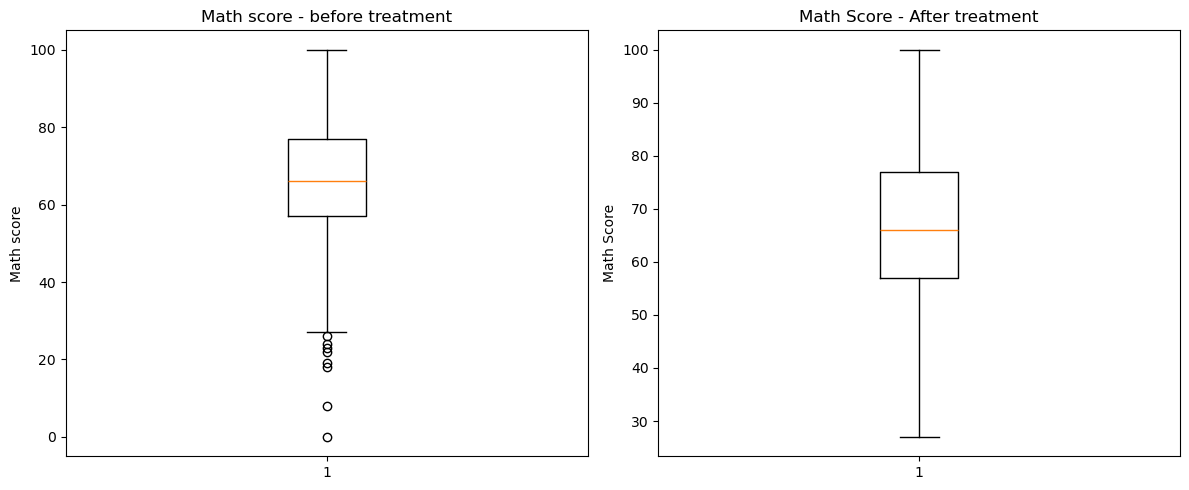

In [29]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.boxplot(df["math score"].dropna())
plt.title("Math score - before treatment")
plt.ylabel("Math score")
plt.subplot(1,2,2)
plt.boxplot(df["math_score_treated"].dropna())
plt.title("Math Score - After treatment")
plt.ylabel("Math Score")
plt.tight_layout()
plt.show()